# Análise Exploratória dos Dados (EDA)

O objetivo desta análise é conhecer a estrutura dos dados, observar as distribuições das variáveis e identificar características relevantes para a classificação dos eventos.

O dataset contém 19.020 observações, 10 características numéricas e uma variável-alvo com duas classes:
- **g:** evento gamma (sinal).
- **h:** evento de hádron (fundo).

## 1. Carregamento dos dados

Como o arquivo original não possui cabeçalho, os nomes das colunas são definidos durante a leitura.

Em seguida, separamos as características em 'X' e a variável-alvo em 'y'.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display

columns = ["fLength", "fWidth", "fSize", "fConc","fConc1", "fAsym", "fM3Long", "fM3Trans","fAlpha", "fDist", "class"]

df = pd.read_csv("../../../data/raw/magic04.data", header=None, names=columns)

X = df.drop(columns='class')
y = df['class']

df.head()


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


## Identificação das variáveis e estatísticas descritivas 

Nessa etapa, verificamos os nomes das colunas, os tipos dos dados e a quantidade de valores não nulos.

As 10 características são numéricas, enquanto a variável-alvo representa a categoria de cada evento.

Calculamos medidas como média, desvio padrão, mínimo, máximo e quartis. 

Essas informações ajudam a comparar as escalas das características, avaliar sua dispersão e identificar valores que merecem investigação.

In [15]:
# Dimensões
print(df.shape)

# Informações gerais e identificação das variáveis
df.info()

# Estatísticas descritivas
display(X.describe().T)


(19020, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  class     19020 non-null  object 
dtypes: float64(10), object(1)
memory usage: 1.6+ MB


,count,mean,std,min,25%,50%,75%,max
fLength,19020.0,53.250154,42.364855,4.2835,24.336000,37.14770,70.122175,334.1770
fWidth,19020.0,22.180966,18.346056,0.0000,11.863800,17.13990,24.739475,256.3820
fSize,19020.0,2.825017,0.472599,1.9413,2.477100,2.73960,3.101600,5.3233
fConc,19020.0,0.380327,0.182813,0.0131,0.235800,0.35415,0.503700,0.8930
fConc1,19020.0,0.214657,0.110511,0.0003,0.128475,0.19650,0.285225,0.6752
fAsym,19020.0,-4.331745,59.206062,-457.9161,-20.586550,4.01305,24.063700,575.2407
fM3Long,19020.0,10.545545,51.000118,-331.7800,-12.842775,15.31410,35.837800,238.3210
fM3Trans,19020.0,0.249726,20.827439,-205.8947,-10.849375,0.66620,10.946425,179.8510
fAlpha,19020.0,27.645707,26.103621,0.0000,5.547925,17.67950,45.883550,90.0000
fDist,19020.0,193.818026,74.731787,1.2826,142.492250,191.85145,240.563825,495.5610


## Distribuição das classes

Verificamos a quantidade e o percentual de observações de cada classe.

A classe 'g' é mais frequente neste dataset. Essa diferença deve ser considerada na divisão dos dados e na avaliação dos classificadores.

,quantidades,percentual
class,,
g,12332,64.84
h,6688,35.16


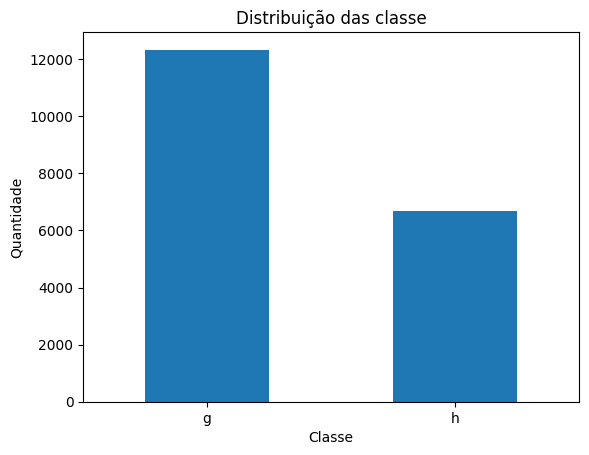

In [16]:
# Distribuição das classes
counts = y.value_counts()

display(pd.DataFrame({
    'quantidades': counts,
    'percentual': (100 * counts / len(y)).round(2)
    }))

counts.plot.bar(title='Distribuição das classe', rot=0)
plt.xlabel('Classe')
plt.ylabel('Quantidade')
plt.show()

## Distribuição das características

Os histogramas mostram como os valores de cada característica estão distribuídos.

Buscamos observar a concentração dos valores, a dispersão, possíveis assimetrias e a presença de valores extremos.

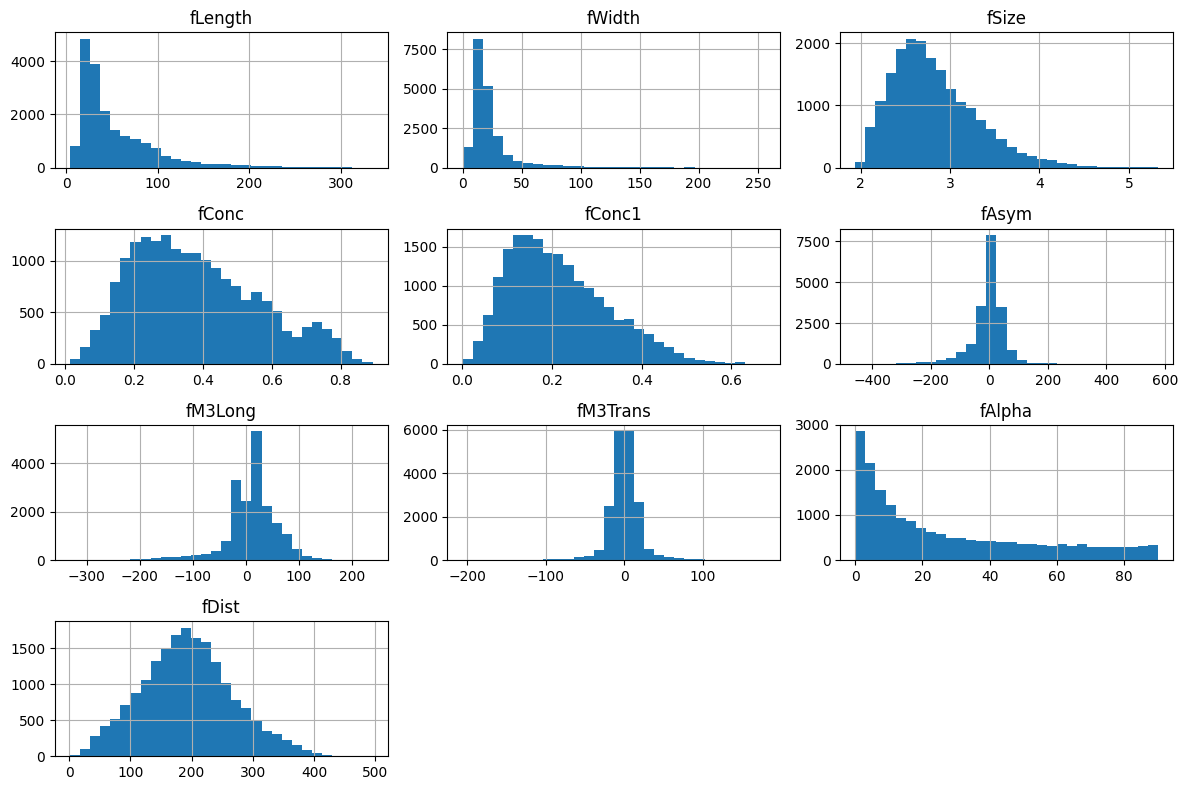

In [17]:
# Histogramas
X.hist(bins=30, figsize=(12,8))
plt.tight_layout()
plt.show()

## Matriz de correlação

A matriz apresenta a correlação de Pearson entre as características, que mede a associação linear entre elas.

- Valores próximos de **1** indicam associação linear positiva forte.
- Valores próximos de **-1** indicam associação linear negativa forte.
- Valores próximos de **0** indicam associação linear fraca.

Uma correlação próxima de zero não exclui relações não lineares.

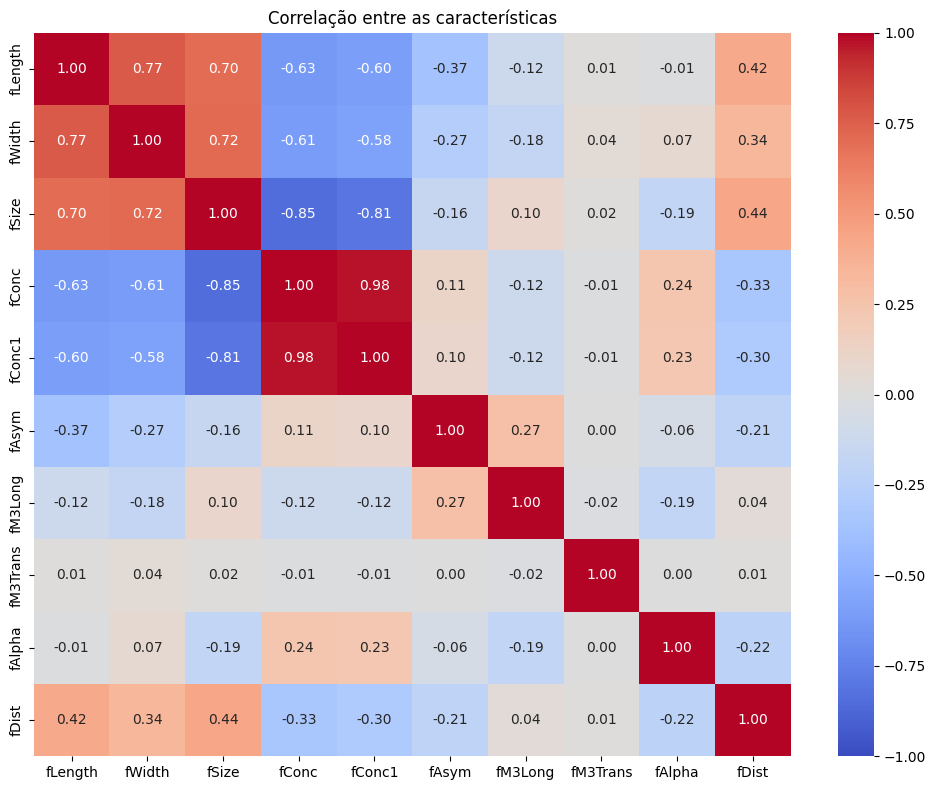

In [18]:
# Matriz de correlação
plt.figure(figsize=(10,8))

sns.heatmap(
    X.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlação entre as características')
plt.tight_layout()
plt.show()

## Valores ausentes

Verificamos a quantidades de valores ausentes em cada coluna para avaliar a necessidade de tratamento.

No arquivo original não foram encontrados valores ausentes.

In [19]:
# Valores ausentes por coluna
display(df.isna().sum())

fLength     0
fWidth      0
fSize       0
fConc       0
fConc1      0
fAsym       0
fM3Long     0
fM3Trans    0
fAlpha      0
fDist       0
class       0
dtype: int64

## Possíveis outliers

Utilizamos boxplots para visualizar a mediana, a dispersão e possíveis valores extremos de cada característica.

Os pontos além dos bigodes são sinalizados pelo critério de 1,5 vezes o intervalo interquartil. Esses pontos não representam necessariamente erros e devem ser avaliados antes de qualquer remoção.

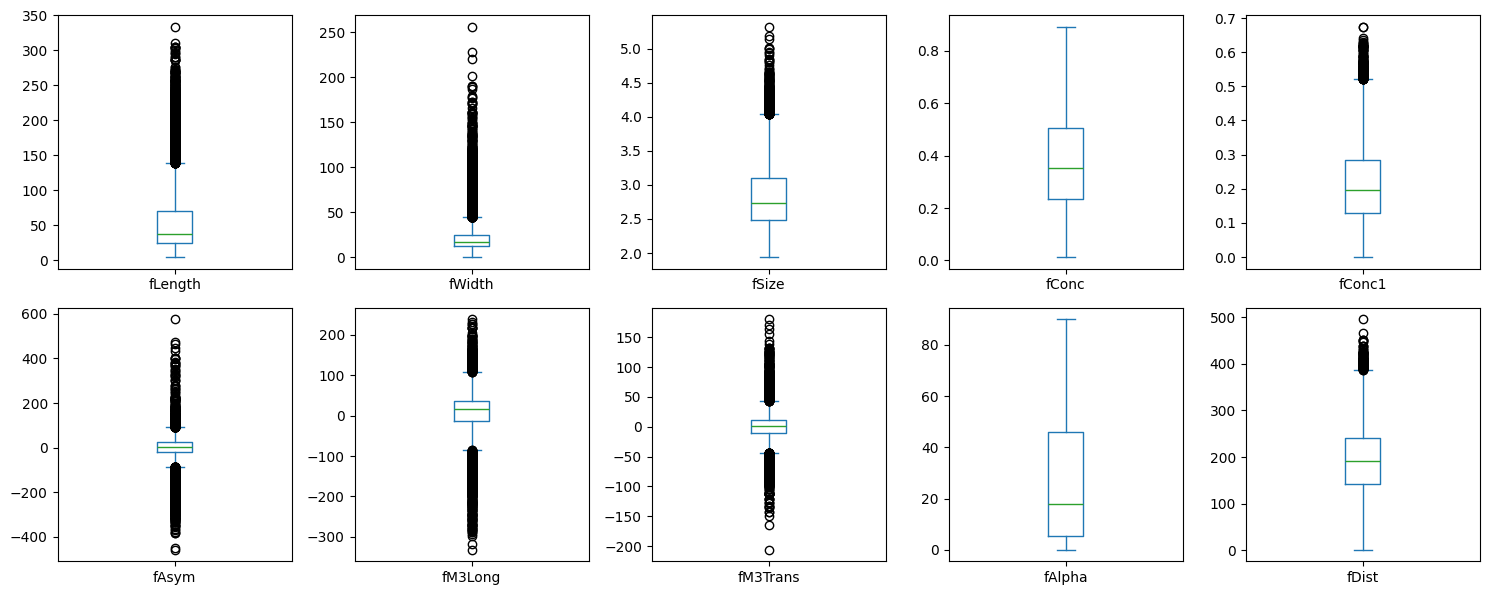

In [20]:
# Boxplots para visualizar possívieis outliers
X.plot.box(
    subplots=True,
    layout=(2, 5),
    figsize=(15, 6),
    sharey=False
)

plt.tight_layout()
plt.show()